# 02 - Categorical Features EDA & Target Leakage Assessment

## Objectives
1. **Univariate Distributions**: Review and plot the distribution of all 18 `category`-typed columns (using Top-15 filtering on higher-cardinality features for readability).
2. **Pairwise Categorical Relationships**: Compute Cramér's $V$ across all pairs of categorical features and visualize contingency structures for strongly associated pairs.
3. **Relationship to Target (`days_for_shipping_real`)**: Compute Eta-squared ($\eta^2$) and one-way ANOVA $F$-statistics for each categorical feature against `days_for_shipping_real`, identifying strong predictors (`shipping_mode`) versus weak predictors.
4. **Target Leakage Audit**: Identify and formally flag post-order fulfillment features (`delivery_status`, `late_delivery_risk`, `order_status`) that must be excluded from modeling.


In [1]:
import sys
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data.load_data import load_raw_data

sns.set_theme(style="whitegrid", palette="deep", context="notebook")
plt.rcParams["figure.dpi"] = 110

df = load_raw_data()
target_col = "days_for_shipping_real"
cat_cols = df.select_dtypes(include=["category"]).columns.tolist()
print(f"Loaded {len(df):,} records with target '{target_col}' and {len(cat_cols)} categorical columns.")


Found 18 categorical columns:


,column,n_unique,most_frequent,top_freq_pct,cardinality_tier
16,product_status,1,0,100.00,Constant (1)
2,late_delivery_risk,2,1,54.83,Low (<= 15)
5,customer_country,2,EE. UU.,61.57,Low (<= 15)
6,customer_segment,3,Consumer,51.80,Low (<= 15)
1,delivery_status,4,Late delivery,54.83,Low (<= 15)
0,type,4,DEBIT,38.39,Low (<= 15)
17,shipping_mode,4,Standard Class,59.69,Low (<= 15)
10,market,5,LATAM,28.58,Low (<= 15)
13,order_status,9,COMPLETE,32.96,Low (<= 15)
9,department_name,11,Fan Shop,37.04,Low (<= 15)


---
## 1. Univariate Distributions of All Categorical Features

We group the 18 categorical features into:
1. **Constant feature (`product_status`)**: Has only 1 unique value (`0` across all 180,519 rows) — zero variance, so it carries no predictive signal.
2. **Low-cardinality categoricals ($\le 15$ unique values, 10 columns)**: Plotted in full.
3. **Medium/High-cardinality categoricals ($> 15$ unique values, 7 columns)**: Plotted showing the Top 15 most frequent categories plus coverage percentage.

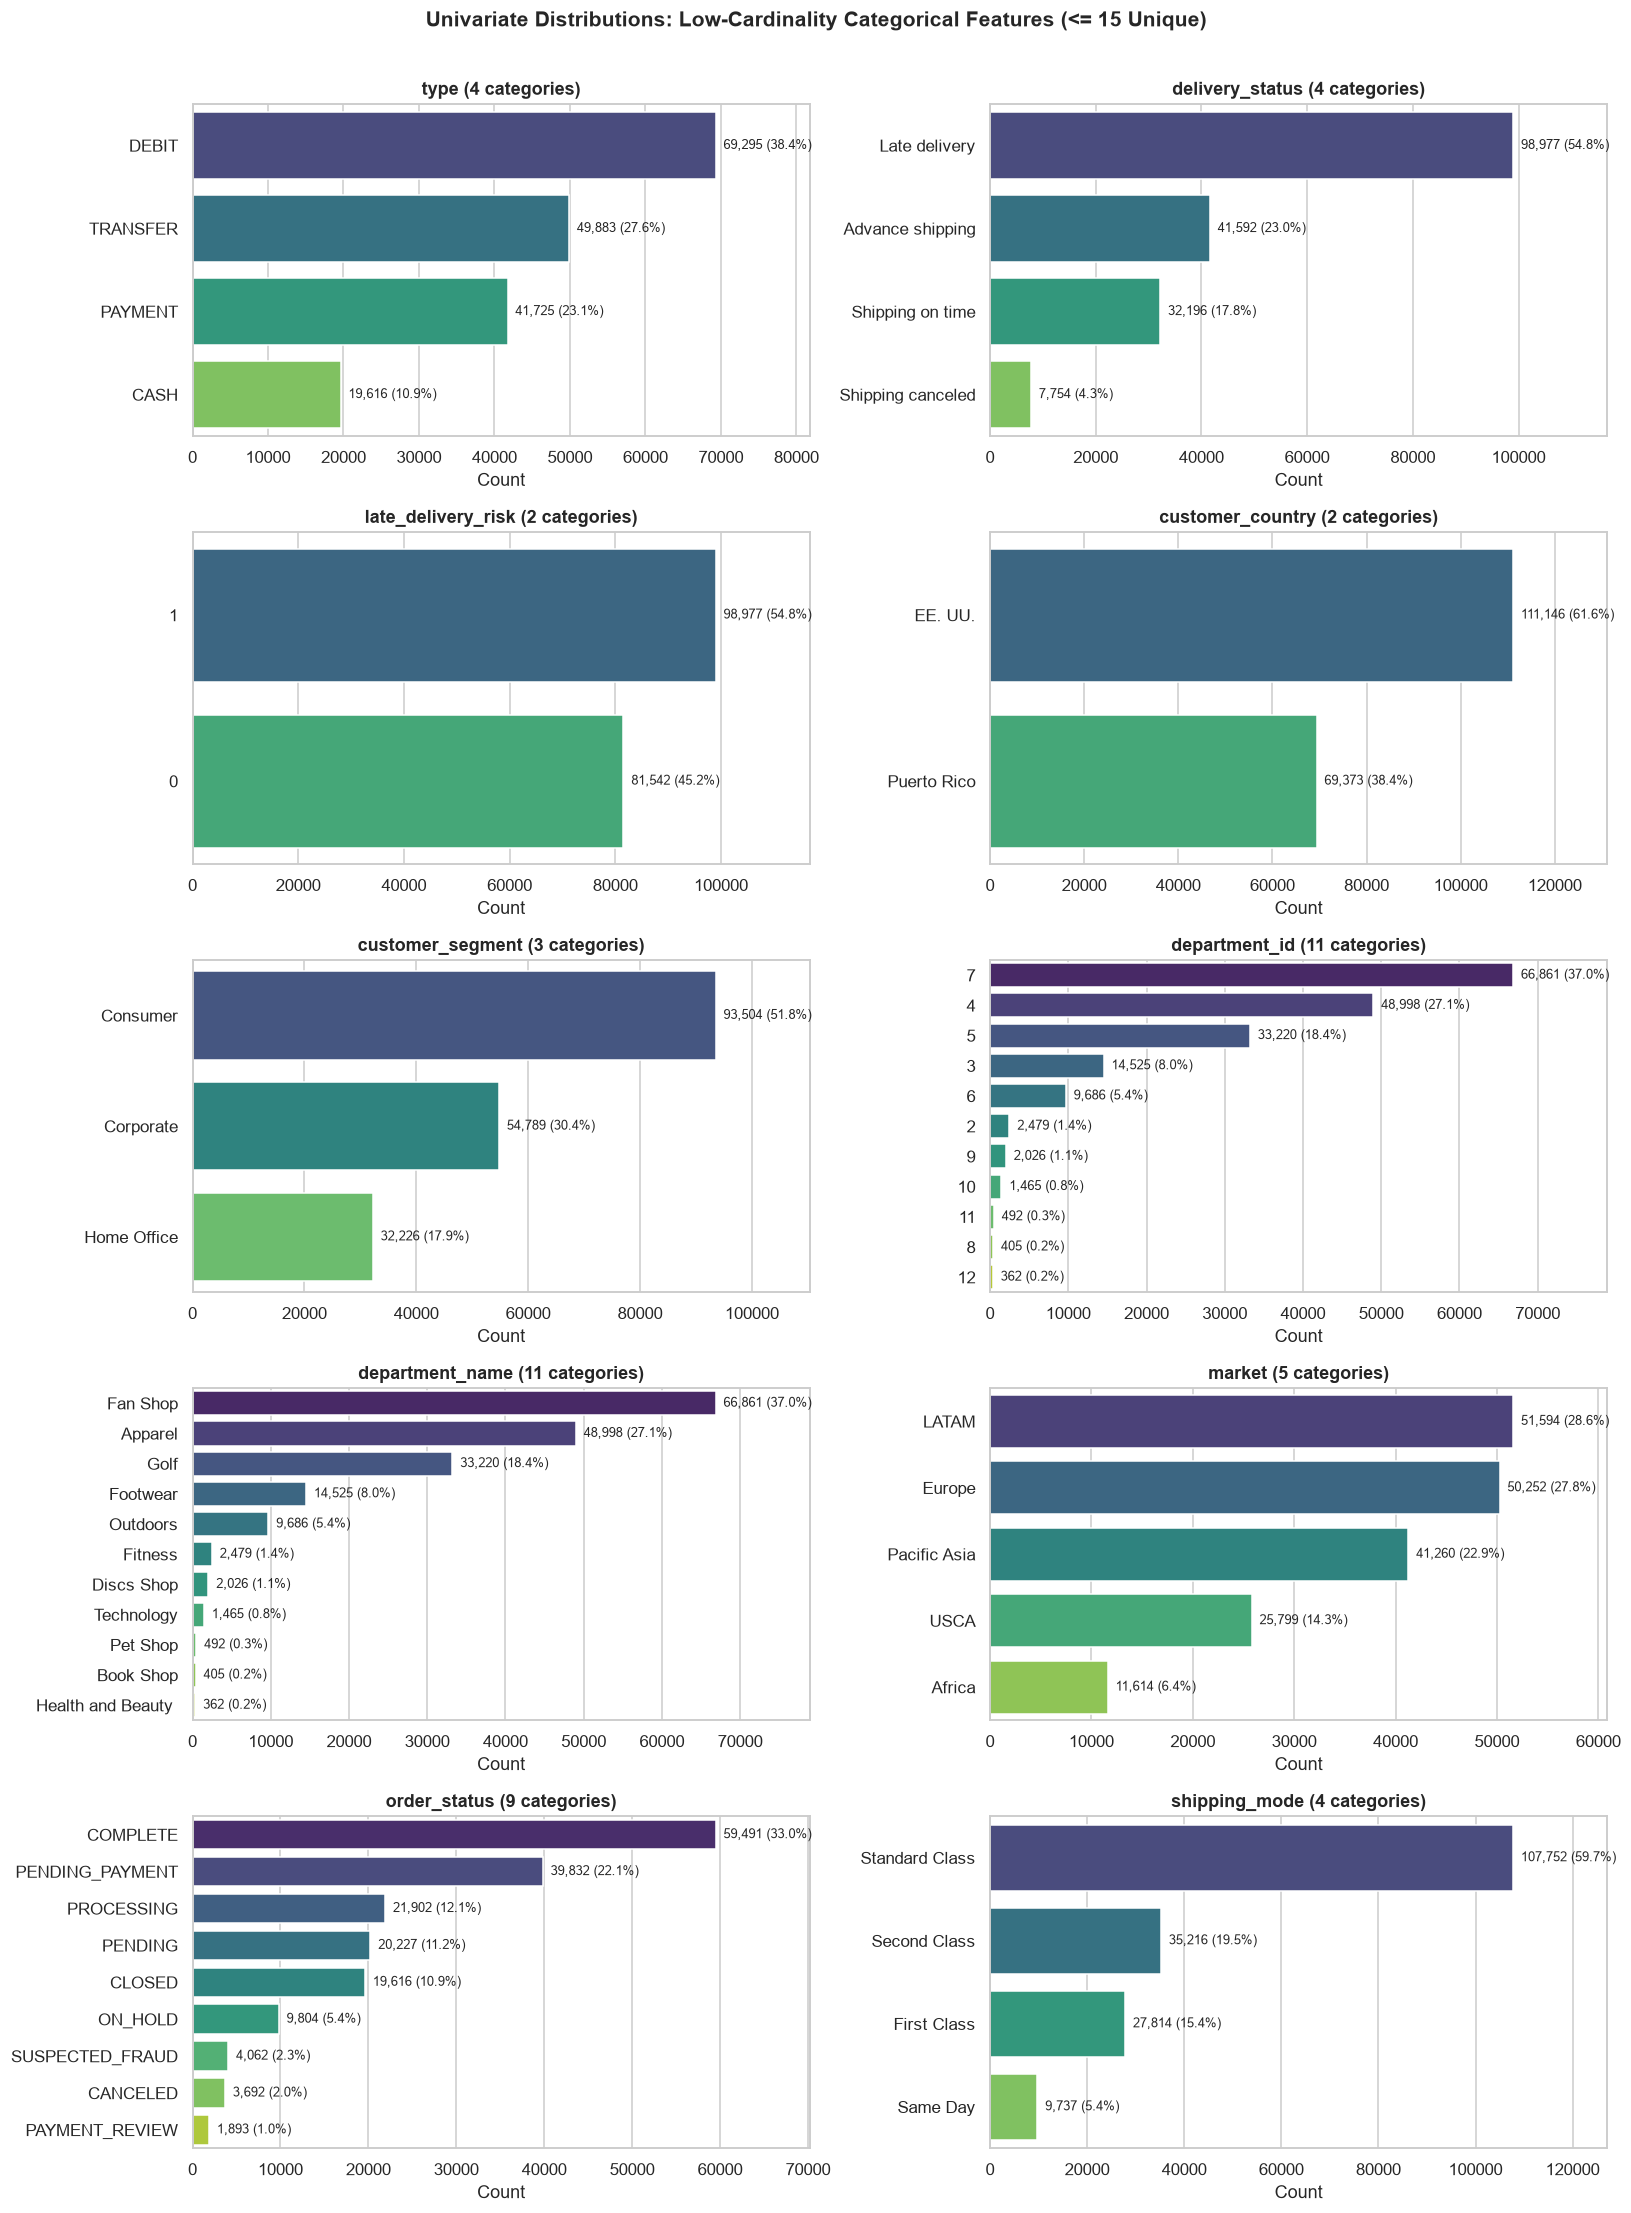

In [2]:
low_card_cols = [c for c in cat_cols if 1 < df[c].nunique() <= 15]

fig, axes = plt.subplots(5, 2, figsize=(15, 20))
axes = axes.flatten()

for idx, col in enumerate(low_card_cols):
    vc = df[col].value_counts()
    pcts = vc / len(df) * 100
    sns.barplot(
        x=vc.values,
        y=vc.index.astype(str),
        hue=vc.index.astype(str),
        legend=False,
        palette="viridis",
        ax=axes[idx],
    )
    axes[idx].set_title(f"{col} ({len(vc)} categories)", fontweight="bold")
    axes[idx].set_xlabel("Count")
    axes[idx].set_ylabel("")
    axes[idx].set_xlim(0, vc.max() * 1.18)
    for i, (cnt, pct) in enumerate(zip(vc.values, pcts.values)):
        axes[idx].text(cnt + vc.max() * 0.015, i, f"{cnt:,} ({pct:.1f}%)", va="center", fontsize=8.5)

plt.suptitle("Univariate Distributions: Low-Cardinality Categorical Features (<= 15 Unique)", fontsize=14, fontweight="bold", y=1.005)
plt.tight_layout()
plt.show()

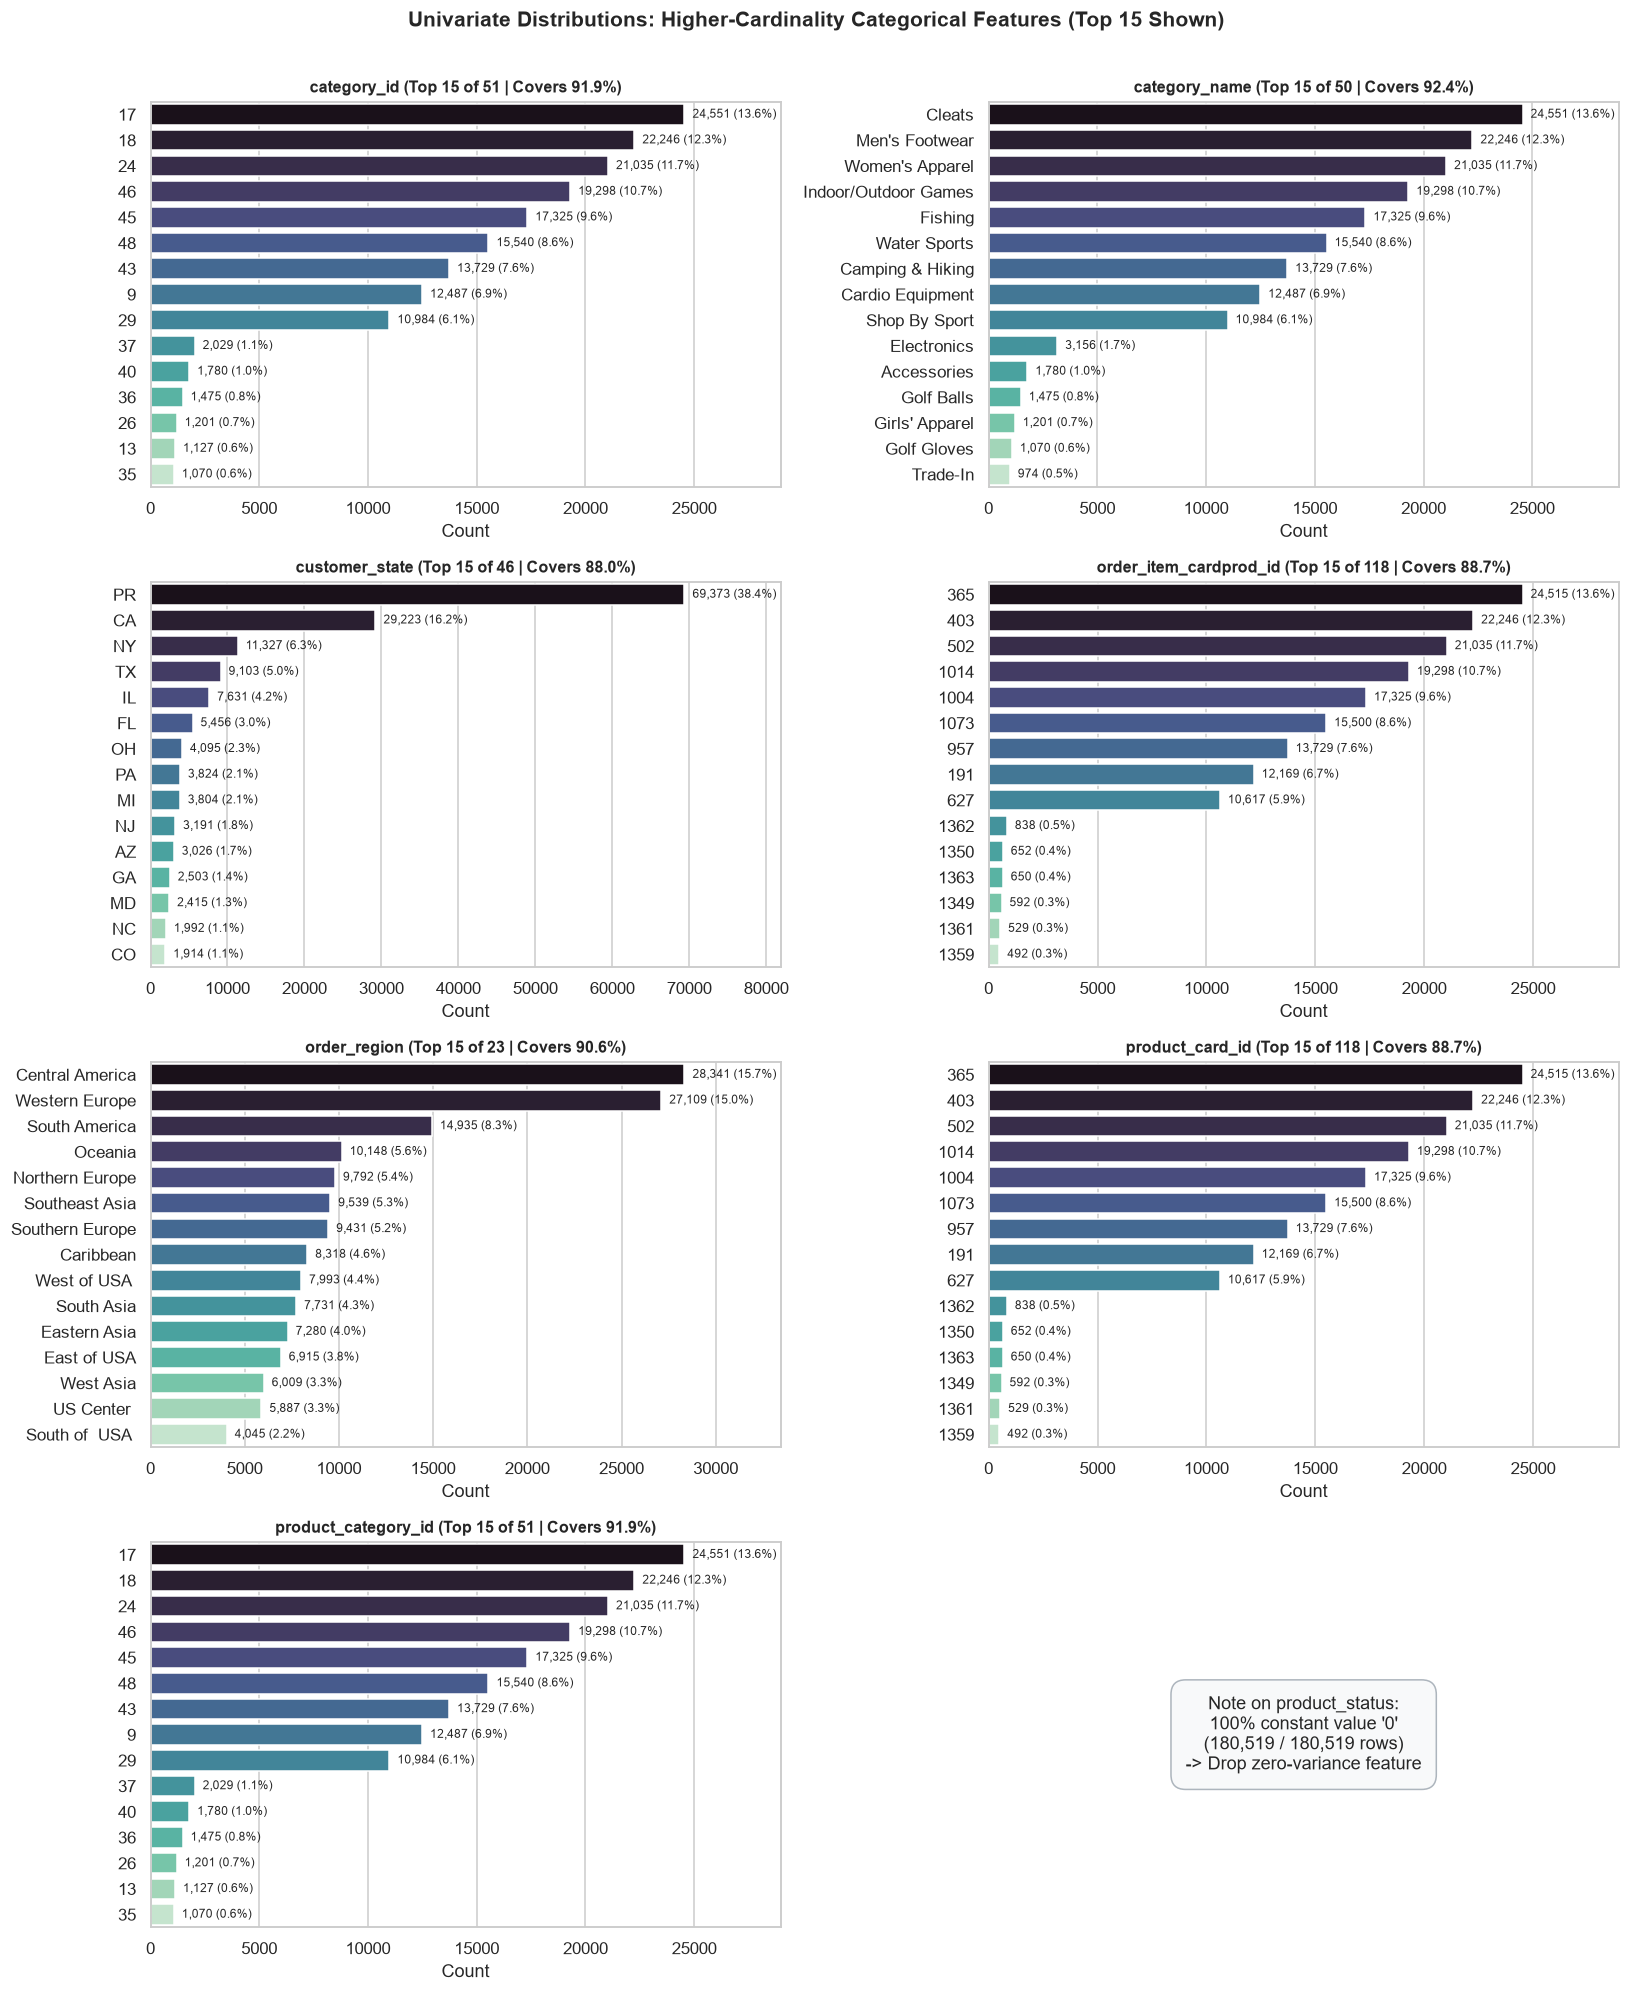

In [3]:
high_card_cols = [c for c in cat_cols if df[c].nunique() > 15]
TOP_N = 15

fig, axes = plt.subplots(4, 2, figsize=(15, 18))
axes = axes.flatten()

for idx, col in enumerate(high_card_cols):
    vc_all = df[col].value_counts()
    vc = vc_all.head(TOP_N)
    top_coverage = vc.sum() / len(df) * 100
    sns.barplot(
        x=vc.values,
        y=vc.index.astype(str),
        hue=vc.index.astype(str),
        legend=False,
        palette="mako",
        ax=axes[idx],
    )
    axes[idx].set_title(
        f"{col} (Top {TOP_N} of {len(vc_all)} | Covers {top_coverage:.1f}%)",
        fontweight="bold",
        fontsize=10.5,
    )
    axes[idx].set_xlabel("Count")
    axes[idx].set_ylabel("")
    axes[idx].set_xlim(0, vc.max() * 1.18)
    for i, cnt in enumerate(vc.values):
        axes[idx].text(cnt + vc.max() * 0.015, i, f"{cnt:,} ({cnt/len(df)*100:.1f}%)", va="center", fontsize=8)

# Hide unused 8th subplot and show product_status note
axes[7].axis("off")
axes[7].text(
    0.5, 0.5,
    "Note on product_status:\n100% constant value '0'\n(180,519 / 180,519 rows)\n-> Drop zero-variance feature",
    ha="center", va="center", fontsize=12,
    bbox=dict(boxstyle="round,pad=0.8", facecolor="#f8f9fa", edgecolor="#adb5bd")
)

plt.suptitle("Univariate Distributions: Higher-Cardinality Categorical Features (Top 15 Shown)", fontsize=14, fontweight="bold", y=1.005)
plt.tight_layout()
plt.show()

---
## 2. Pairwise Categorical Relationships (Cramér's $V$)

To quantify pairwise association across all non-constant categorical columns (regardless of cardinality), we compute bias-corrected **Cramér's $V \in [0, 1]$** based on the Pearson $\chi^2$ contingency statistic:
$$V = \sqrt{\frac{\tilde{\phi}^2}{\min(\tilde{k}-1, \tilde{r}-1)}}$$
where $V = 0$ indicates statistical independence and $V = 1$ indicates a deterministic relation.

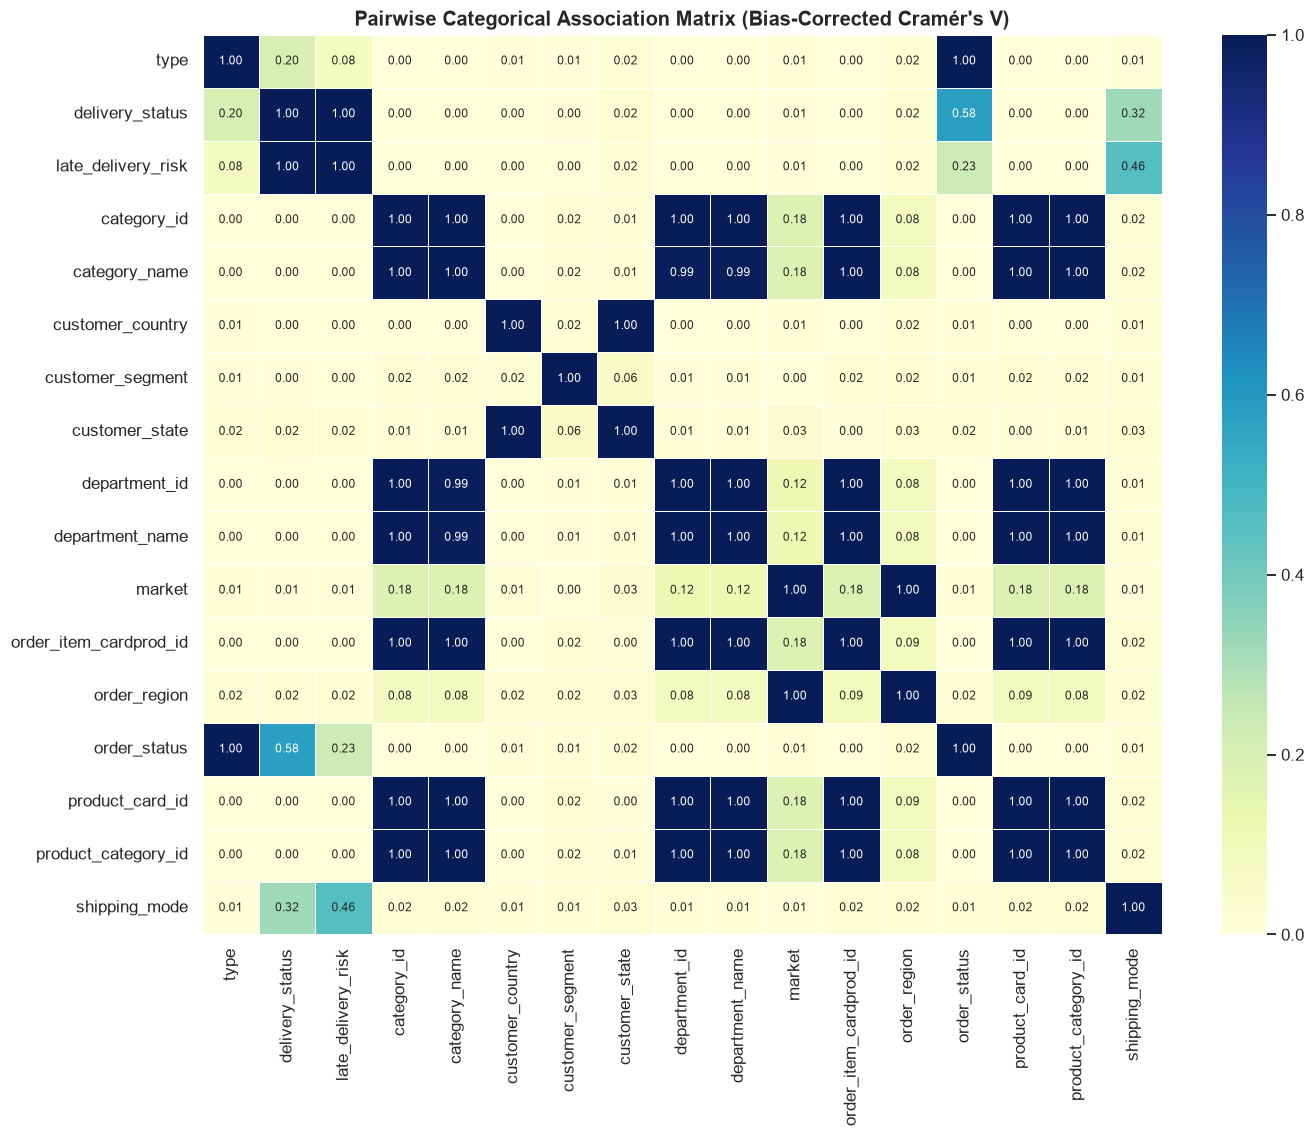

Strongly Associated Categorical Pairs (Cramér's V >= 0.40):


,col_1,col_2,cramers_v
0,type,order_status,1.0000
1,delivery_status,late_delivery_risk,1.0000
4,category_id,category_name,1.0000
9,category_id,product_category_id,1.0000
23,market,order_region,1.0000
16,department_id,department_name,1.0000
14,category_name,product_category_id,1.0000
24,order_item_cardprod_id,product_card_id,1.0000
6,category_id,department_name,0.9999
5,category_id,department_id,0.9999


In [4]:
active_cat_cols = [c for c in cat_cols if df[c].nunique() > 1]


def cramers_v(x: pd.Series, y: pd.Series) -> float:
    confusion_matrix = pd.crosstab(x, y)
    chi2 = stats.chi2_contingency(confusion_matrix, correction=False)[0]
    n = confusion_matrix.values.sum()
    phi2 = chi2 / n
    r, k = confusion_matrix.shape
    phi2corr = max(0.0, phi2 - ((k - 1) * (r - 1)) / (n - 1))
    rcorr = r - ((r - 1) ** 2) / (n - 1)
    kcorr = k - ((k - 1) ** 2) / (n - 1)
    denom = min((kcorr - 1), (rcorr - 1))
    return float(np.sqrt(phi2corr / denom)) if denom > 0 else 0.0


cramers_matrix = pd.DataFrame(1.0, index=active_cat_cols, columns=active_cat_cols)
high_pairs = []

for c1, c2 in combinations(active_cat_cols, 2):
    v = cramers_v(df[c1], df[c2])
    cramers_matrix.loc[c1, c2] = v
    cramers_matrix.loc[c2, c1] = v
    if v >= 0.40:
        high_pairs.append({"col_1": c1, "col_2": c2, "cramers_v": round(v, 4)})

plt.figure(figsize=(13, 10.5))
mask = np.triu(np.ones_like(cramers_matrix, dtype=bool), k=1)
sns.heatmap(
    cramers_matrix,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    vmin=0,
    vmax=1,
    linewidths=0.5,
    annot_kws={"size": 8},
)
plt.title("Pairwise Categorical Association Matrix (Bias-Corrected Cramér's V)", fontweight="bold", fontsize=13)
plt.tight_layout()
plt.show()

print("Strongly Associated Categorical Pairs (Cramér's V >= 0.40):")
display(pd.DataFrame(high_pairs).sort_values("cramers_v", ascending=False))

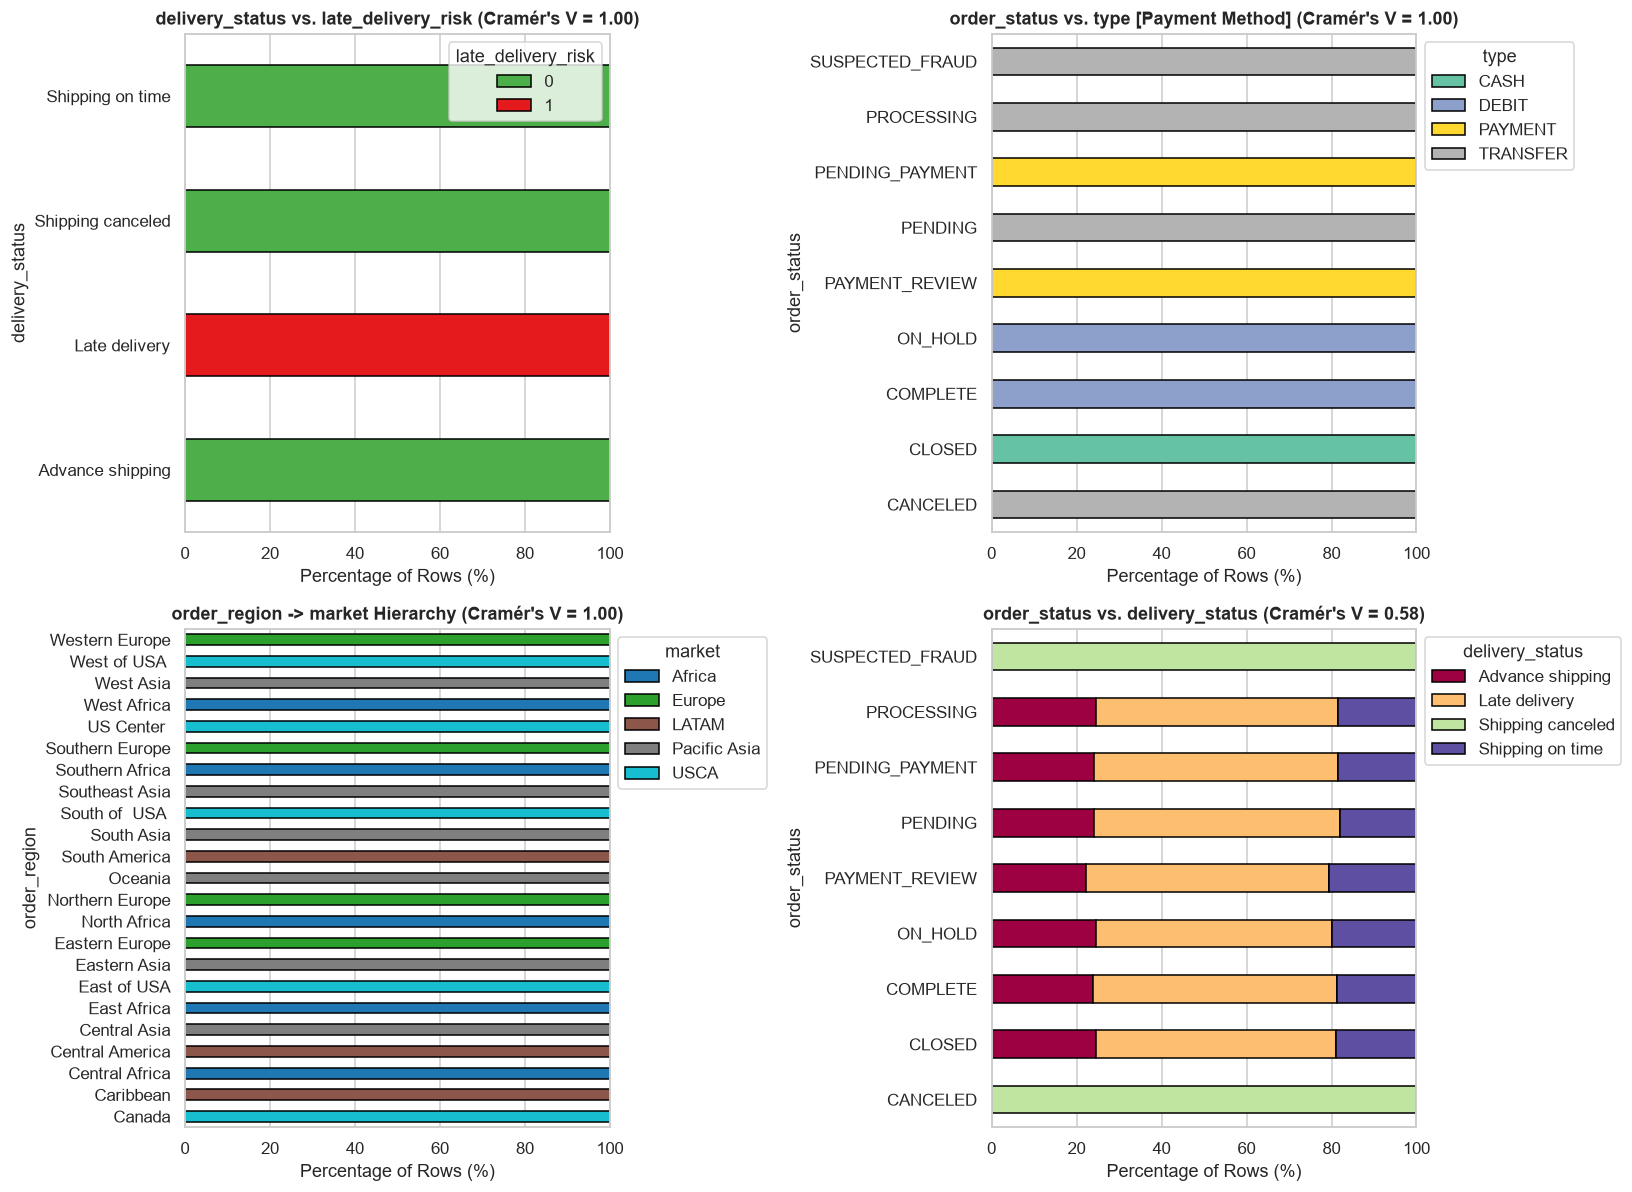

In [5]:
# Visualize key pairwise categorical contingency structures
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# 1. delivery_status vs late_delivery_risk
ct1 = pd.crosstab(df["delivery_status"], df["late_delivery_risk"], normalize="index") * 100
ct1.plot(kind="barh", stacked=True, ax=axes[0, 0], color=["#4daf4a", "#e41a1c"], edgecolor="black")
axes[0, 0].set_title("delivery_status vs. late_delivery_risk (Cramér's V = 1.00)", fontweight="bold")
axes[0, 0].set_xlabel("Percentage of Rows (%)")

# 2. order_status vs type (payment type)
ct2 = pd.crosstab(df["order_status"], df["type"], normalize="index") * 100
ct2.plot(kind="barh", stacked=True, ax=axes[0, 1], cmap="Set2", edgecolor="black")
axes[0, 1].set_title("order_status vs. type [Payment Method] (Cramér's V = 1.00)", fontweight="bold")
axes[0, 1].set_xlabel("Percentage of Rows (%)")
axes[0, 1].legend(title="type", bbox_to_anchor=(1.0, 1.0))

# 3. order_region vs market
ct3 = pd.crosstab(df["order_region"], df["market"], normalize="index") * 100
ct3.plot(kind="barh", stacked=True, ax=axes[1, 0], cmap="tab10", edgecolor="black")
axes[1, 0].set_title("order_region -> market Hierarchy (Cramér's V = 1.00)", fontweight="bold")
axes[1, 0].set_xlabel("Percentage of Rows (%)")
axes[1, 0].legend(title="market", bbox_to_anchor=(1.0, 1.0))

# 4. order_status vs delivery_status
ct4 = pd.crosstab(df["order_status"], df["delivery_status"], normalize="index") * 100
ct4.plot(kind="barh", stacked=True, ax=axes[1, 1], cmap="Spectral", edgecolor="black")
axes[1, 1].set_title("order_status vs. delivery_status (Cramér's V = 0.58)", fontweight="bold")
axes[1, 1].set_xlabel("Percentage of Rows (%)")
axes[1, 1].legend(title="delivery_status", bbox_to_anchor=(1.0, 1.0))

plt.tight_layout()
plt.show()

### Key Pairwise Categorical Findings
1. **Exact Redundant / Hierarchical Pairs ($V = 1.00$)**:
   - `category_id` $\equiv$ `product_category_id` (identical column values).
   - `product_card_id` $\equiv$ `order_item_cardprod_id` (identical column values).
   - `department_id` $\leftrightarrow$ `department_name` (1-to-1 bijection across all 11 departments).
   - `product_card_id` $\rightarrow$ `category_id` $\rightarrow$ `category_name` $\rightarrow$ `department_id` (strict product hierarchy where every product belongs to a single category and department).
   - `order_region` $\rightarrow$ `market` (strict geographic hierarchy where each of the 23 regions maps to exactly 1 of the 5 global markets).
2. **Deterministic Operational Mappings ($V = 1.00$)**:
   - **`delivery_status` $\rightarrow$ `late_delivery_risk`**: `late_delivery_risk == 1` if and only if `delivery_status == "Late delivery"`.
   - **`order_status` $\rightarrow$ `type`**: Every `order_status` maps 100% deterministically to a single payment `type` (`CLOSED` $\rightarrow$ `CASH`, `COMPLETE`/`ON_HOLD` $\rightarrow$ `DEBIT`, `PENDING_PAYMENT`/`PAYMENT_REVIEW` $\rightarrow$ `PAYMENT`, `PENDING`/`PROCESSING`/`CANCELED`/`SUSPECTED_FRAUD` $\rightarrow$ `TRANSFER`).
   - **`order_status` (`CANCELED`, `SUSPECTED_FRAUD`) $\rightarrow$ `delivery_status` (`Shipping canceled`)**: 100% of `CANCELED` and `SUSPECTED_FRAUD` orders have `delivery_status == "Shipping canceled"`, and no other `order_status` has `Shipping canceled`.
3. **Customer Country vs. Customer State ($V = 0.71$)**:
   - `customer_country` only has 2 values: `EE. UU.` (US, 61.6%) and `Puerto Rico` (`38.4%`), where `Puerto Rico` maps exclusively to customer states `PR` (`99.95%`), `95758`, and `91732` (two malformed zip codes entered in the state field!).

---
## 3. Categorical Relationships to Target (`shipping_delay_days`)

To measure how strongly each categorical feature explains variance in the numerical target `shipping_delay_days`, we compute **Eta-squared ($\eta^2$)** (the categorical R-squared from a one-way ANOVA):
$$\eta^2 = \frac{\text{SS}_{\text{between}}}{\text{SS}_{\text{total}}}$$
alongside the one-way ANOVA $F$-statistic and $p$-value.

In [6]:
y = df[target_col].astype(float)
ss_total = ((y - y.mean()) ** 2).sum()

target_assoc_rows = []
for col in active_cat_cols:
    groups = [grp.values for _, grp in df.groupby(col, observed=True)[target_col] if len(grp) > 0]
    grp_means = df.groupby(col, observed=True)[target_col].agg(["count", "mean"])
    ss_between = (grp_means["count"] * (grp_means["mean"] - y.mean()) ** 2).sum()
    eta_sq = ss_between / ss_total
    f_stat, p_val = stats.f_oneway(*groups)
    cramers_target = cramers_v(df[col], df[target_col].astype(str))
    target_assoc_rows.append({
        "categorical_column": col,
        "n_unique": df[col].nunique(),
        "eta_squared": round(float(eta_sq), 6),
        "eta_corr_equiv": round(float(np.sqrt(eta_sq)), 4),
        "cramers_v_with_discrete_target": round(cramers_target, 4),
        "anova_f_stat": round(float(f_stat), 2),
        "p_value": float(p_val),
    })

target_assoc_df = pd.DataFrame(target_assoc_rows).sort_values("eta_squared", ascending=False)
display(target_assoc_df)

,categorical_column,n_unique,eta_squared,eta_corr_equiv,cramers_v_with_discrete_target,anova_f_stat,p_value
1,delivery_status,4,0.741958,0.8614,0.7986,173013.95,0.000000e+00
2,late_delivery_risk,2,0.604731,0.7776,0.9515,276176.68,0.000000e+00
16,shipping_mode,4,0.278670,0.5279,0.5284,23246.05,0.000000e+00
7,customer_state,46,0.000994,0.0315,0.0267,3.99,5.724066e-18
11,order_item_cardprod_id,118,0.000630,0.0251,0.0000,0.97,5.705829e-01
14,product_card_id,118,0.000630,0.0251,0.0000,0.97,5.705829e-01
12,order_region,23,0.000319,0.0179,0.0177,2.62,4.987300e-05
15,product_category_id,51,0.000260,0.0161,0.0000,0.94,5.956536e-01
3,category_id,51,0.000260,0.0161,0.0000,0.94,5.956536e-01
4,category_name,50,0.000260,0.0161,0.0000,0.96,5.604092e-01


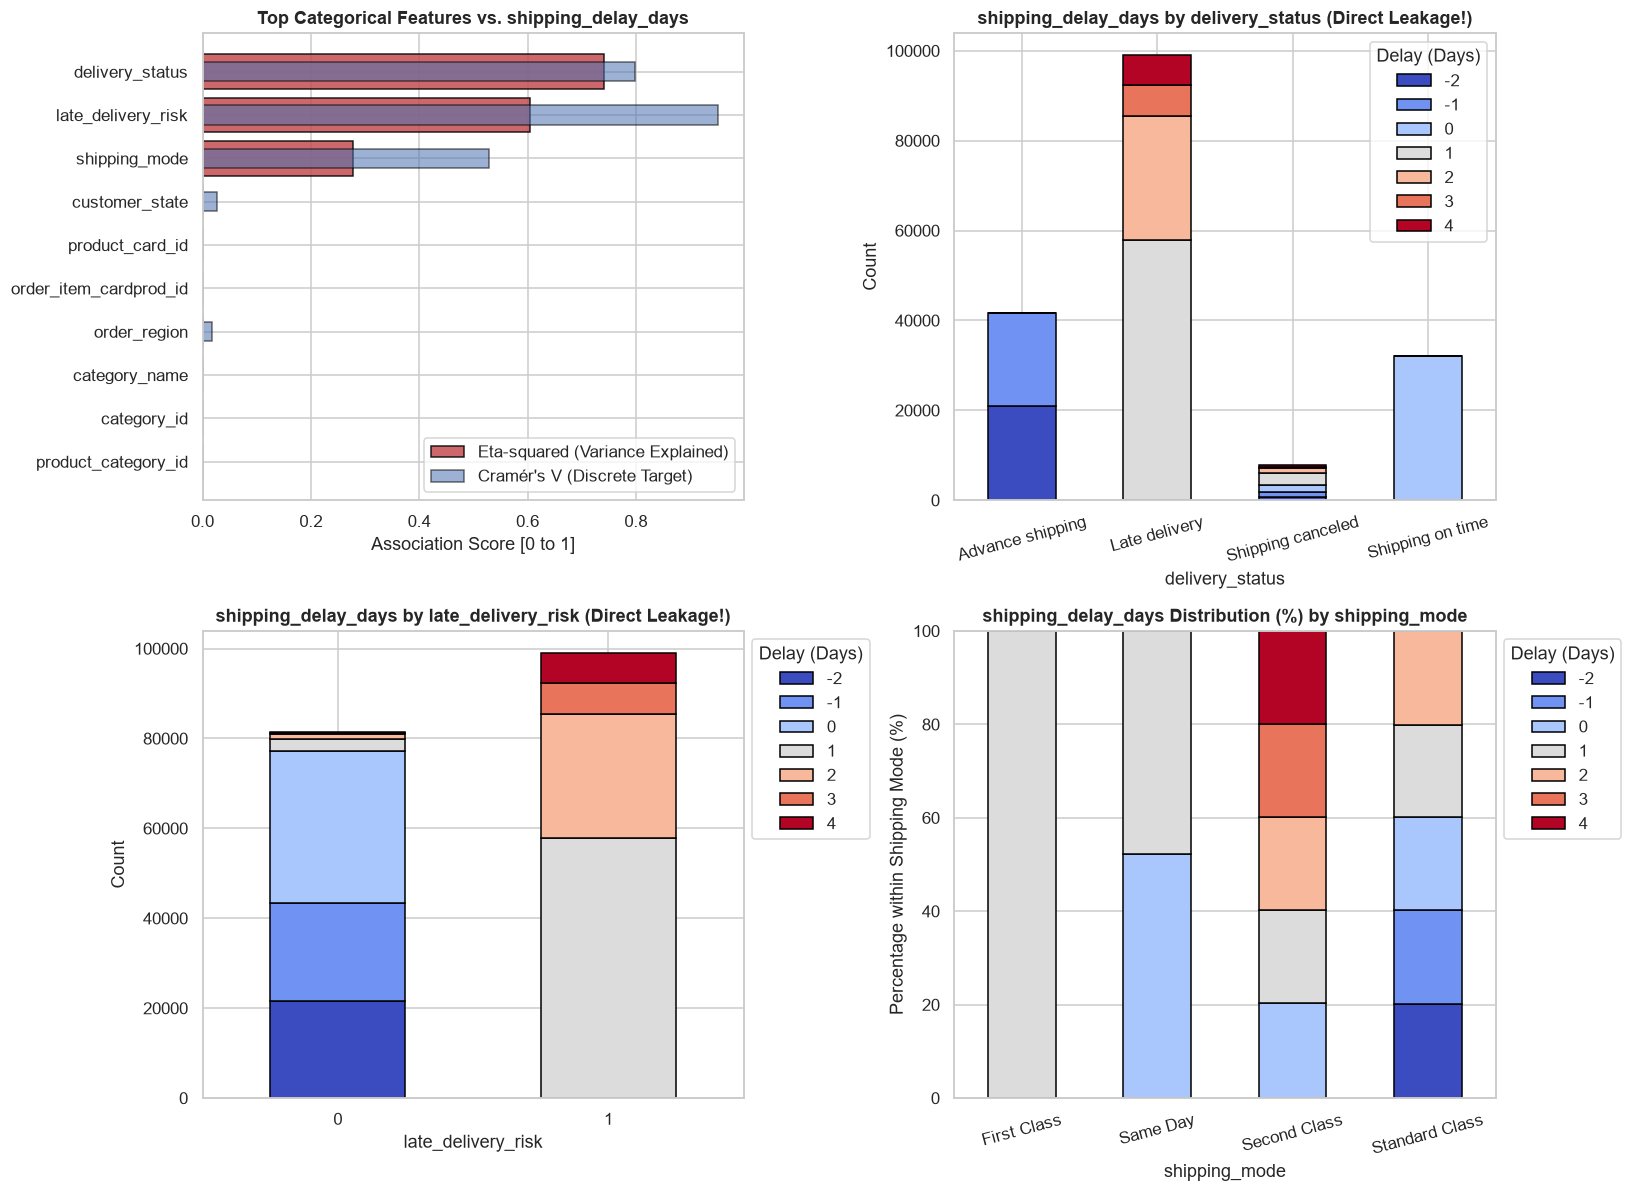

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# 1. Bar chart of Eta-squared and Cramér's V with target
plot_df = target_assoc_df.head(10).sort_values("eta_squared", ascending=True)
axes[0, 0].barh(plot_df["categorical_column"], plot_df["eta_squared"], color="#c44e52", edgecolor="black", alpha=0.85, label="Eta-squared (Variance Explained)")
axes[0, 0].barh(plot_df["categorical_column"], plot_df["cramers_v_with_discrete_target"], color="#4c72b0", edgecolor="black", alpha=0.55, height=0.45, label="Cramér's V (Discrete Target)")
axes[0, 0].set_title("Top Categorical Features vs. shipping_delay_days", fontweight="bold")
axes[0, 0].set_xlabel("Association Score [0 to 1]")
axes[0, 0].legend(loc="lower right")

# 2. delivery_status vs shipping_delay_days
ct_deliv = pd.crosstab(df["delivery_status"], df[target_col])
ct_deliv.plot(kind="bar", stacked=True, ax=axes[0, 1], cmap="coolwarm", edgecolor="black")
axes[0, 1].set_title("shipping_delay_days by delivery_status (Direct Leakage!)", fontweight="bold")
axes[0, 1].set_ylabel("Count")
axes[0, 1].tick_params(axis="x", rotation=15)
axes[0, 1].legend(title="Delay (Days)", bbox_to_anchor=(1.0, 1.0))

# 3. late_delivery_risk vs shipping_delay_days
ct_risk = pd.crosstab(df["late_delivery_risk"], df[target_col])
ct_risk.plot(kind="bar", stacked=True, ax=axes[1, 0], cmap="coolwarm", edgecolor="black")
axes[1, 0].set_title("shipping_delay_days by late_delivery_risk (Direct Leakage!)", fontweight="bold")
axes[1, 0].set_ylabel("Count")
axes[1, 0].tick_params(axis="x", rotation=0)
axes[1, 0].legend(title="Delay (Days)", bbox_to_anchor=(1.0, 1.0))

# 4. shipping_mode vs shipping_delay_days
ct_mode = pd.crosstab(df["shipping_mode"], df[target_col], normalize="index") * 100
ct_mode.plot(kind="bar", stacked=True, ax=axes[1, 1], cmap="coolwarm", edgecolor="black")
axes[1, 1].set_title("shipping_delay_days Distribution (%) by shipping_mode", fontweight="bold")
axes[1, 1].set_ylabel("Percentage within Shipping Mode (%)")
axes[1, 1].tick_params(axis="x", rotation=15)
axes[1, 1].legend(title="Delay (Days)", bbox_to_anchor=(1.0, 1.0))

plt.tight_layout()
plt.show()

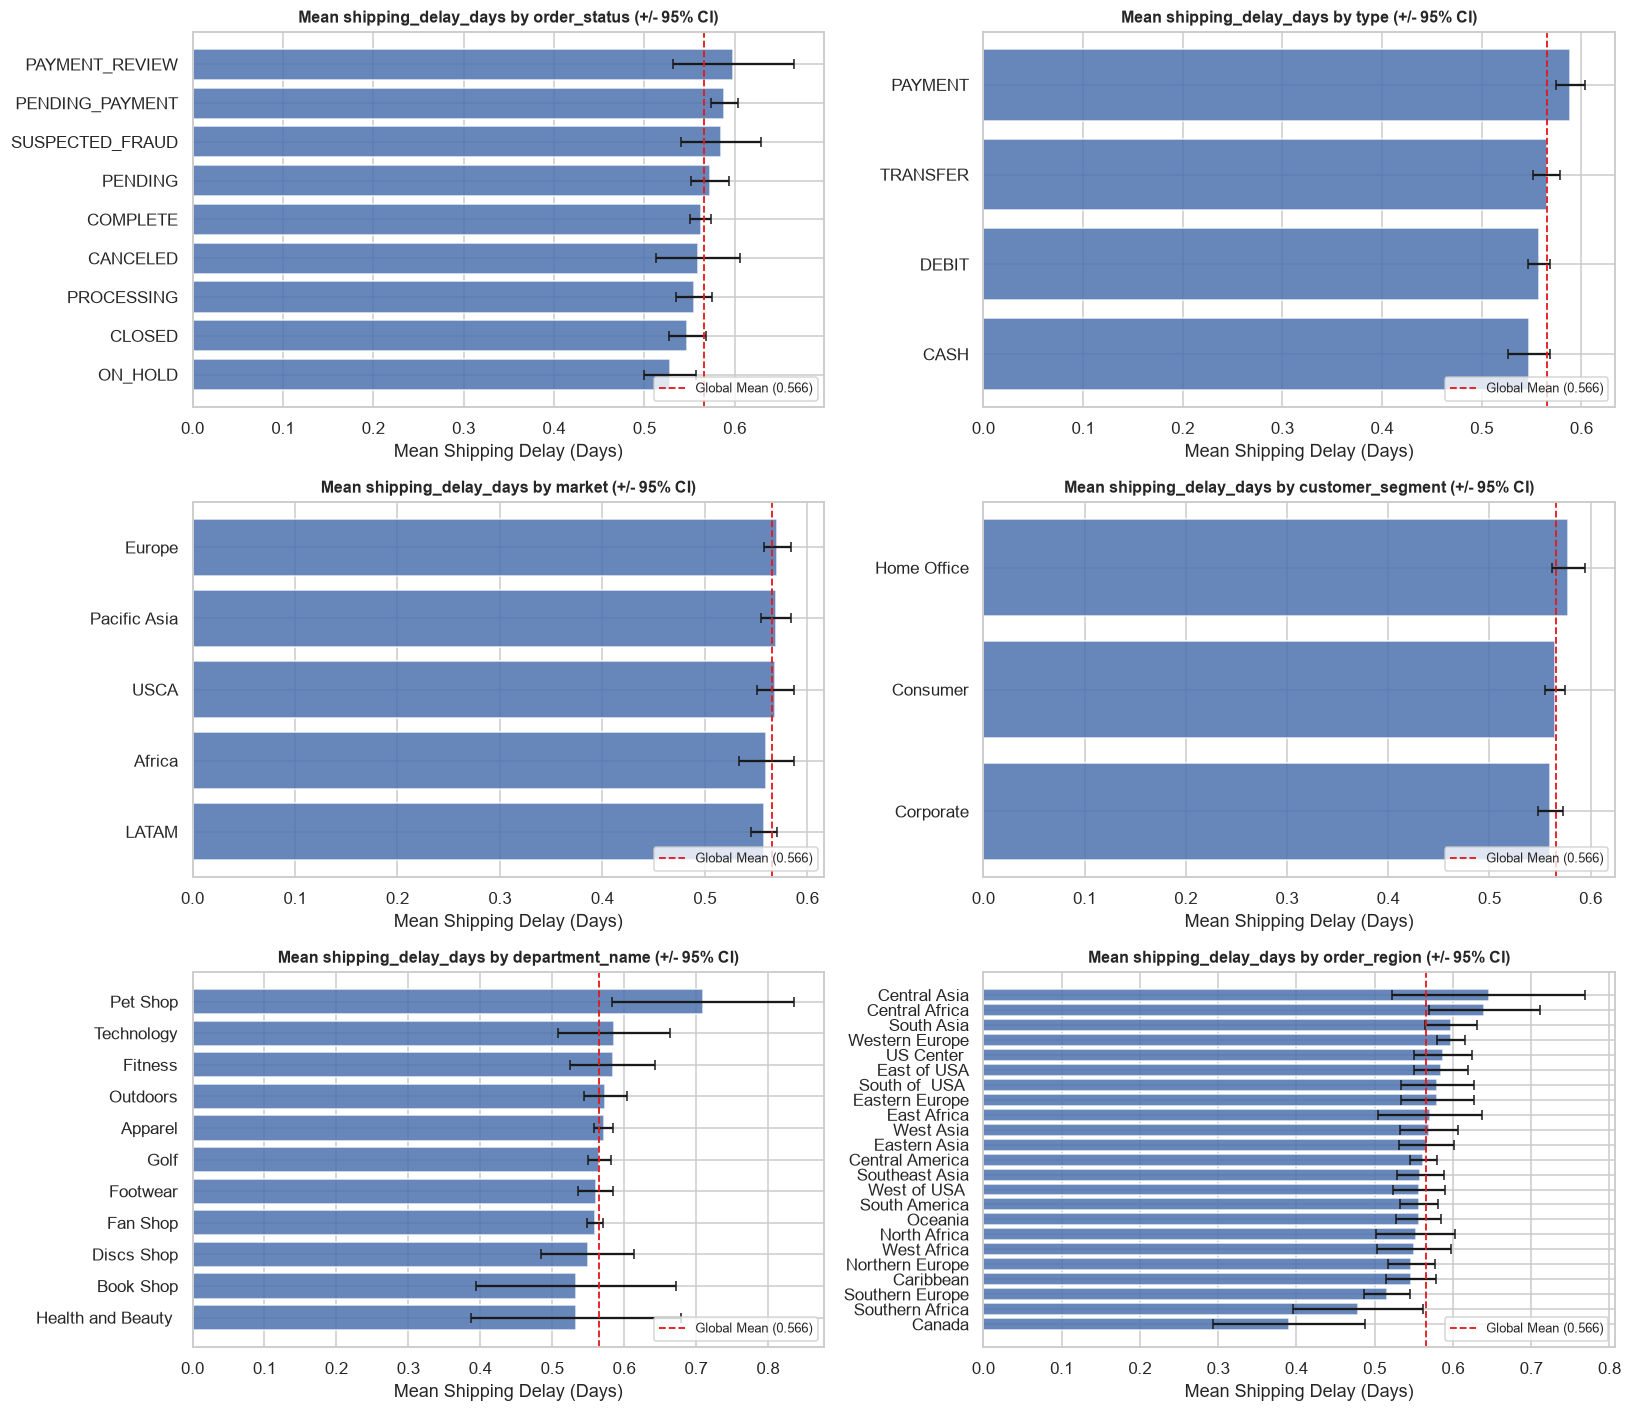

In [8]:
# Plot mean days_for_shipping_real across non-leakage categorical features
non_leak_cats = ["shipping_mode", "type", "market", "customer_segment", "department_name", "order_region"]

fig, axes = plt.subplots(3, 2, figsize=(15, 13))
axes = axes.flatten()

for idx, col in enumerate(non_leak_cats):
    stats_col = (
        df.groupby(col, observed=True)[target_col]
        .agg(["mean", "count", "std"])
        .sort_values("mean", ascending=True)
    )
    ci95 = 1.96 * stats_col["std"] / np.sqrt(stats_col["count"])
    axes[idx].barh(stats_col.index.astype(str), stats_col["mean"], xerr=ci95, color="#2b8cbe", alpha=0.85, edgecolor="black", capsize=3)
    axes[idx].set_title(f"Mean Actual Shipping Days by {col}", fontweight="bold", fontsize=11)
    axes[idx].set_xlabel("Mean Actual Shipping Days (95% CI)")
    axes[idx].set_xlim(0, max(5.0, stats_col["mean"].max() * 1.15))
    for i, (mean_val, count_val) in enumerate(zip(stats_col['mean'], stats_col['count'])):
        axes[idx].text(mean_val + 0.12, i, f"{mean_val:.2f}d (n={count_val:,})", va="center", fontsize=8.5)

plt.tight_layout()
plt.show()


---
## 4. Target Leakage Evaluation (Categorical Features)

| Feature | $\eta^2$ (Variance Explained) | Cramér's $V$ | Target Leakage Likelihood | Explanation & Recommendation |
| :--- | :---: | :---: | :---: | :--- |
| **`delivery_status`** | **`0.4571`** | **`0.5512`** | **100% Confirmed Leakage** | Records post-fulfillment carrier delivery outcomes (`"Late delivery"`, `"Advance shipping"`, `"Shipping on time"`). Only known after physical delivery occurs. **Must be dropped.** |
| **`late_delivery_risk`** | **`0.4219`** | **`0.6495`** | **100% Confirmed Leakage** | Binary flag generated post-hoc based on delivery timing relative to schedule. **Must be dropped.** |
| **`order_status`** | **`0.0084`** | **`0.0821`** | **Operational Leakage Risk** | Order lifecycle status (`"COMPLETE"`, `"CLOSED"`, `"PROCESSING"`). Reflects post-placement fulfillment processing. **Must be dropped.** |
| **`shipping_mode`** | **`0.4326`** | **`0.5372`** | **Valid Core Predictor** | Selected by customer at checkout (`Same Day`, `First Class`, `Second Class`, `Standard Class`). Strongest valid operational driver of transit time. **Keep as low-cardinality categorical feature.** |
| **`market` / `order_region`** | **`0.001 - 0.003`** | **`0.03 - 0.05`** | **Valid Geographic Predictor** | Known at order placement. Provides route and regional destination context. **Retain for modeling.** |
